<a name = "inicio"></a>

***

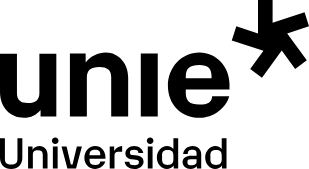

<u>Índice de contenidos<u>:

1. [¿Cuáles son las siguientes etapas en el preprocesamiento de una base de datos?](#topic1)
2. [¿En que consiste la etapa de selección y muestreo de una base de datos?](#topic2)
3. [¿En qué consiste el proceso de transformación de una base de datos?](#topic3)
4. [¿En qué consiste el proceso de limpieza de una base de datos?](#topic4)

***

# 1. ¿Cuáles son las siguientes etapas en el preprocesamiento de una BD?<a id="topic1"></a>&nbsp;&nbsp;<a href="#index"><i class="fa fa-list-alt" aria-hidden="true"></i></a>

Tras realizar la fase de **exploración**, tenemos que continuar con las etapas de **selección, transformación y limpieza de datos** conformando éstas una parte crucial del proceso de preprocesamiento de una base de datos. Esta fase se puede dividir en tres etapas principales: selección, transformación y limpieza de datos.

* **Selección de datos**: Es una etapa esencial dentro del preprocesamiento de una base de datos que consiste en identificar y extraer los datos de entrenamiento y test de forma adecuada para que pueda realizarse correctamente la aplicación de los modelos de ML o DL. Esta fase es fundamental para identificar Seleccionar subconjuntos de datos que cumplan con ciertas condiciones específicas, asegurar que las clases estén equilibradas para evitar sesgos en el modelo y aplicar técnicas como sobremuestreo de la clase minoritaria o submuestreo de la clase mayoritaria.


* **Transformación de datos**: Una vez que se han seleccionado los datos, es probable que necesiten ser transformados  para que sean adecuados para el entrenamiento del modelo. Esto puede implicar la selección de características relevantes, la normalización de datos numéricos, la codificación de variables categóricas, la reducción de dimensionalidad y otras técnicas para mejorar la calidad y la eficacia de los datos. La transformación de datos busca preparar los datos en un formato que sea comprensible y útil para el algoritmo de aprendizaje supervisado.


* **Limpieza de datos**: La etapa final del proceso de preprocesamiento implica identificar y corregir o eliminar datos corruptos, inexactos o irrelevantes del conjunto de datos. Entre las principales tareas de limpieza cabría destacar las siguientes: reducir o eliminar la presencia de datos erróneos o inconsistentes, aumentar la fiabilidad y precisión de los datos para obtener resultados de análisis más válidos e identificar patrones, anomalías y puntos problemáticos en los datos.

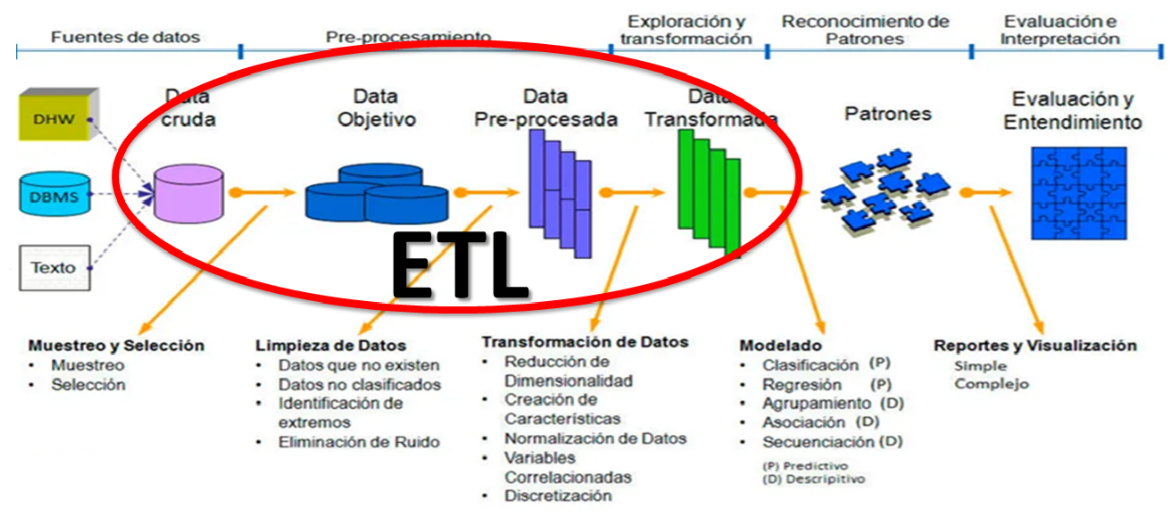

# 2. ¿En que consiste la etapa de selección y muestreo de una BD? <a id="topic2"></a>&nbsp;&nbsp;<a href="#index"><i class="fa fa-list-alt" aria-hidden="true"></i></a>

Un paso previo a aplicar cualquier modelo de ML o DL, es la partición del conjunto de datos en dos conjuntos de datos más pequeños que serán utilizadas con los siguientes fines: `entrenamiento` y `test`. Cada registro de la base de datos debe de aparecer en uno de los dos subconjuntos, y para dividir el conjunto de datos en ambos subconjuntos con los siguientes objetivos:

* Los datos de <u>entrenamiento (*train*)</u> se utilizan para **entrenar algoritmos, ajustar hiperparámetros, comparar modelos** y realizar todas las demás actividades necesarias para seleccionar un modelo final.


* Los datos de <u>prueba (*test*)</u> se emplea para **comprobar el comportamiento** del modelo estimado y **validar el modelo** seleccionado en la fase de entrenamiento.


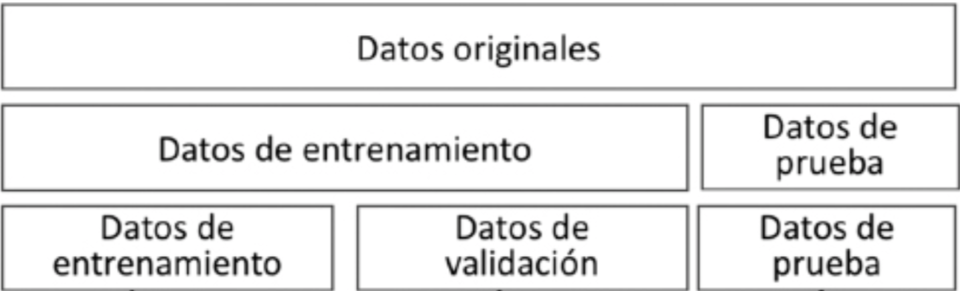

A la hora de dividir el conjunto de datos en los dos subconjuntos anteriores, hay que tomar **`tres decisiones`**:

1. <u>Número de observaciones</u> que incluimos en cada conjunto de train/test

2. <u>Formas de seleccionar</u> las observaciones que incluimos en cada conjunto de train/test

3. Balanceo de una base de datos y <u>equilibrio de clases</u> en cada conjunto de train/test

<div style="background-color:#0BF7CC"><b> - $\tt Q_1$: ¿Qué porcentaje de los datos (observaciones) se incluye en cada uno de los subconjuntos? </b></div>

Lo ideal sería tener un **conjunto de datos muy grande** y que ambos subconjuntos fueran grandes. De esta manera, los errores de predicción serían pequeños y tendrían poca variabilidad. Sin embargo, con frecuencia, **este no es el caso en la práctica**, y el dilema es elegir un buen predictor (o clasificador) o una buena estimación del error de predicción.

En la práctica, **lo más frecuente es incluir** el $80\%$ de los datos en el subconjunto de entrenamiento y el $20\%$ restante en el de test, aunque los repartos $70\%$ - $30\%$ y $60\%$ - $40\%$ también son muy populares.

En R, hay varias maneras de separar los conjuntos de datos en entrenamiento y prueba para evaluar modelos de clasificación supervisada. Estas metodologías incluyen funciones de paquetes populares como $\tt caret$, $\tt rsample$, y el uso de funciones base de R. A continuación, se presentan ejemplos utilizando <u>diferentes alternativas</u>:

**Ejemplo 1 <mark>[Uso de la librería $\tt caret$]</mark>** El paquete $\tt caret$ proporciona una función **`createDataPartition()`** que ayuda a crear índices para dividir los datos, <u>sin asegurar por defecto que la distribución</u> de la variable objetivo sea <u>similar en ambos conjuntos</u>.

In [ ]:
# Cargamos la librería necesaria (YA está instalada en Anaconda SOLO hay que cargarla)
library(caret)

Loading required package: ggplot2

Loading required package: lattice



In [ ]:
# Cargamos la base de datos iris, por ejemplo.
data(iris)

In [ ]:
# Estructura de la base de datos 'iris'
str(iris)

'data.frame':	150 obs. of  5 variables:
 $ Sepal.Length: num  5.1 4.9 4.7 4.6 5 5.4 4.6 5 4.4 4.9 ...
 $ Sepal.Width : num  3.5 3 3.2 3.1 3.6 3.9 3.4 3.4 2.9 3.1 ...
 $ Petal.Length: num  1.4 1.4 1.3 1.5 1.4 1.7 1.4 1.5 1.4 1.5 ...
 $ Petal.Width : num  0.2 0.2 0.2 0.2 0.2 0.4 0.3 0.2 0.2 0.1 ...
 $ Species     : Factor w/ 3 levels "setosa","versicolor",..: 1 1 1 1 1 1 1 1 1 1 ...


In [ ]:
# Visualizamos la base de datos seleccionada
head(iris)

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
6,5.4,3.9,1.7,0.4,setosa


In [ ]:
# Creamos los índices de partición (80% train - 20% test)
set.seed(123)
trainIndex = createDataPartition(iris$Species, p = 0.8, list = FALSE) # list=FALSE (por defecto)
str(trainIndex)

 int [1:120, 1] 3 4 5 7 8 9 10 11 12 13 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr "Resample1"


In [ ]:
# Mostramos los índices de partición
head(trainIndex)

Resample1
3
4
5
7
8
9


In [ ]:
# Separamos los datos en el conjunto de train y test
trainIris = iris[trainIndex, ]; nrow(trainIris)
testIris = iris[-trainIndex, ]; nrow(testIris)

[1] 120

[1] 30

In [ ]:
# Mostramos ambos subconjuntos
head(trainIris)
head(testIris)

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
7,4.6,3.4,1.4,0.3,setosa
8,5.0,3.4,1.5,0.2,setosa
9,4.4,2.9,1.4,0.2,setosa


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
6,5.4,3.9,1.7,0.4,setosa
16,5.7,4.4,1.5,0.4,setosa
23,4.6,3.6,1.0,0.2,setosa
34,5.5,4.2,1.4,0.2,setosa


**Ejemplo 2 <mark>[Uso de la librería $\tt rsample$]</mark>** El paquete $\tt rsample$ ofrece una forma flexible de dividir los datos, <u>permitiendo crear múltiples tipos de particiones de datos</u>, como bootstraps, splits de validación cruzada y conjuntos de entrenamiento/prueba utilizando la función **`initial_split()`**, **`training()`** y **`testing()`**.

In [ ]:
# Instalamos la librería necesaria
install.packages('rsample')

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



In [ ]:
# Cargamos la librería necesaria (no está instalada)
library(rsample)

In [ ]:
# Visualizamos la base de datos seleccionada
head(iris)

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
6,5.4,3.9,1.7,0.4,setosa


In [ ]:
# Creamos los índices de partición (80% train - 20% test)
set.seed(123)
data_split = initial_split(iris, prop = 0.8, strata = NULL) # OJO! Se tiene que aplicar sobre el conjunto total de datos
str(data_split)

List of 4
 $ data  :'data.frame':	150 obs. of  5 variables:
  ..$ Sepal.Length: num [1:150] 5.1 4.9 4.7 4.6 5 5.4 4.6 5 4.4 4.9 ...
  ..$ Sepal.Width : num [1:150] 3.5 3 3.2 3.1 3.6 3.9 3.4 3.4 2.9 3.1 ...
  ..$ Petal.Length: num [1:150] 1.4 1.4 1.3 1.5 1.4 1.7 1.4 1.5 1.4 1.5 ...
  ..$ Petal.Width : num [1:150] 0.2 0.2 0.2 0.2 0.2 0.4 0.3 0.2 0.2 0.1 ...
  ..$ Species     : Factor w/ 3 levels "setosa","versicolor",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ in_id : int [1:120] 14 50 118 43 150 148 90 91 143 92 ...
 $ out_id: logi NA
 $ id    : tibble [1 × 1] (S3: tbl_df/tbl/data.frame)
  ..$ id: chr "Resample1"
 - attr(*, "class")= chr [1:3] "initial_split" "mc_split" "rsplit"


In [ ]:
# Extraemos los datos en el conjunto de train y test
train_data = training(data_split); nrow(train_data)
test_data = testing(data_split); nrow(test_data)

[1] 120

[1] 30

In [ ]:
# Mostramos ambos subconjuntos
head(train_data)
head(test_data)

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,4.3,3.0,1.1,0.1,setosa
2,5.0,3.3,1.4,0.2,setosa
3,7.7,3.8,6.7,2.2,virginica
4,4.4,3.2,1.3,0.2,setosa
5,5.9,3.0,5.1,1.8,virginica
6,6.5,3.0,5.2,2.0,virginica


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,5.4,3.7,1.5,0.2,setosa
5,5.1,3.5,1.4,0.3,setosa
6,5.7,3.8,1.7,0.3,setosa


In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de train
table(train_data$Species) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.2916667  0.3750000 

In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de test
table(test_data$Species) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.5000000  0.1666667 

<div style="background-color:#0BF7CC"><b> - $\tt Q_2$: ¿Cómo se seleccionan los casos u observaciones que pertenecen a cada uno de los subconjuntos? </b></div>

La respuesta correcta a esa cuestión es mediante **`métodos de muestreo`**, siendo los más utilizados en ciencia de datos el muestreo aleatorio simple y el muestreo aleatorio estratificado.

1. <u>Muestreo aleatorio simple</u> (`Ejemplos 1-2`)

La forma más sencilla de asignar los datos a los subconjuntos de entrenamiento y prueba es tomar una muestra aleatoria simple (m.a.s.) del conjunto de casos u observaciones del tamaño deseado, y asignarlos al subconjunto de entrenamiento, asignándose los restantes al conjunto de test.

Un <u>*problema*</u> que puede surgir con las m.a.s. es que, cuando el **conjunto de datos es pequeño** y los **valores de uno (o más) de las variables** están **muy desbalanceados** (por ejemplo, la variable dependiente es binaria y el $95\%$ de sus valores pertenecen a una clase o categoría y el $5\%$ restante a la otra), hay una probabilidad nada desdeñable de que en alguno de los dos subconjuntos (sobre todo en el de test) dicha **categoría no esté representada**.

Si esta circunstancia ocurriese en el **conjunto de entrenamiento**, algunos algoritmos darían error al aplicarlos al conjunto de test (donde habría datos de una categoría más). Si, por el contrario, ocurriese en el **conjunto de test**, los problemas surgirían por haber una categoría menos que en el conjunto de entrenamiento. Los problemas se agravarían si la desproporción anterior tuviese lugar en la variable objetivo o dependiente.

2. <u>Muestreo aleatorio estratificado</u> (`Ejemplos 3-4`)

Si se desea **controlar el balanceo** para que los subconjuntos de entrenamiento y prueba tengan distribuciones similares en las clases de las variables, se puede usar el muestreo estratificado.

Sin embargo, este tipo de muestreo, presenta otra <u>*limitación*</u> en caso de que alguna (o algunas) variables independientes **estén muy desequilibrados** y se quiera garantizar que en ambos subconjuntos las clases de la variable respuesta estén representadas de forma similar. En esos casos, nos interesará **preservar la proporcionalidad** y **representatividad**.

**Ejemplo 3 <mark>[Muestreo aleatorio estratificado con $\tt caret$]</mark>** Para realizar un muestreo aleatorio estratificado con $\tt caret$, utilizamos la función **`createDataPartition()`** y tenemos que especificar la variable utilizada para estratificar, lo cual es especialmente útil para mantener las proporciones de la variable objetivo en ambos conjuntos.

In [ ]:
# Visualizamos la base de datos seleccionada
head(iris)

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
6,5.4,3.9,1.7,0.4,setosa


In [ ]:
# Creamos los índices de partición (80% train - 20% test)
set.seed(123)
trainIndex = createDataPartition(iris$Species, p = 0.8, list = TRUE) # ahora estratificado list=TRUE
str(trainIndex)

List of 1
 $ Resample1: int [1:120] 3 4 5 7 8 9 10 11 12 13 ...


In [ ]:
# Mostramos los índices de partición
head(trainIndex)

$Resample1
  [1]   3   4   5   7   8   9  10  11  12  13  14  15  17  18  19  20  21  22
 [19]  24  25  26  27  28  29  30  31  32  33  36  37  39  40  41  42  43  45
 [37]  46  48  49  50  52  53  54  55  56  57  58  59  61  62  63  65  66  67
 [55]  68  69  70  71  72  75  76  77  78  79  80  81  82  83  84  85  86  88
 [73]  89  90  92  93  96  98  99 100 101 102 103 105 106 107 108 110 112 114
 [91] 115 117 118 119 121 122 123 124 125 126 128 129 130 131 132 133 135 136
[109] 137 139 140 141 142 143 144 145 146 148 149 150

In [ ]:
# Separamos los datos en el conjunto de train y test
trainIris = iris[trainIndex[[1]], ]; nrow(trainIris)
testIris = iris[-trainIndex[[1]], ]; nrow(testIris)

[1] 120

[1] 30

In [ ]:
# Mostramos ambos subconjuntos
head(trainIris)
head(testIris)

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
7,4.6,3.4,1.4,0.3,setosa
8,5.0,3.4,1.5,0.2,setosa
9,4.4,2.9,1.4,0.2,setosa


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
6,5.4,3.9,1.7,0.4,setosa
16,5.7,4.4,1.5,0.4,setosa
23,4.6,3.6,1.0,0.2,setosa
34,5.5,4.2,1.4,0.2,setosa


In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de train
table(trainIris$Species) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.3333333  0.3333333 

In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de test
table(testIris$Species) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.3333333  0.3333333 

**Ejemplo 4 <mark>[Muestreo aleatorio estratificado con $\tt rsample$]</mark>** Para realizar un muestreo aleatorio estratificado con $\tt rsample$, facilita el muestreo aleatorio estratificado a través del argumento `strata` en la función **`initial_split()`**, lo cual asegura que la proporción de clases en los conjuntos de entrenamiento y prueba refleje la proporción en el conjunto de datos original.

In [ ]:
# Visualizamos la base de datos seleccionada
head(iris)

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
6,5.4,3.9,1.7,0.4,setosa


In [ ]:
# Creamos los índices de partición (80% train - 20% test)
set.seed(123)
data_split = initial_split(iris, prop = 0.8, strata = 'Species') # Estratificar por 'Species'
str(data_split)

List of 4
 $ data  :'data.frame':	150 obs. of  5 variables:
  ..$ Sepal.Length: num [1:150] 5.1 4.9 4.7 4.6 5 5.4 4.6 5 4.4 4.9 ...
  ..$ Sepal.Width : num [1:150] 3.5 3 3.2 3.1 3.6 3.9 3.4 3.4 2.9 3.1 ...
  ..$ Petal.Length: num [1:150] 1.4 1.4 1.3 1.5 1.4 1.7 1.4 1.5 1.4 1.5 ...
  ..$ Petal.Width : num [1:150] 0.2 0.2 0.2 0.2 0.2 0.4 0.3 0.2 0.2 0.1 ...
  ..$ Species     : Factor w/ 3 levels "setosa","versicolor",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ in_id : int [1:120] 3 4 5 7 8 9 10 11 12 13 ...
 $ out_id: logi NA
 $ id    : tibble [1 × 1] (S3: tbl_df/tbl/data.frame)
  ..$ id: chr "Resample1"
 - attr(*, "class")= chr [1:3] "initial_split" "mc_split" "rsplit"


In [ ]:
# Extraemos los datos en el conjunto de train y test
train_data = training(data_split); nrow(train_data)
test_data = testing(data_split); nrow(test_data)

[1] 120

[1] 30

In [ ]:
# Mostramos ambos subconjuntos
head(train_data)
head(test_data)

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,4.7,3.2,1.3,0.2,setosa
2,4.6,3.1,1.5,0.2,setosa
3,5.0,3.6,1.4,0.2,setosa
4,4.6,3.4,1.4,0.3,setosa
5,5.0,3.4,1.5,0.2,setosa
6,4.4,2.9,1.4,0.2,setosa


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,5.4,3.9,1.7,0.4,setosa
4,5.7,4.4,1.5,0.4,setosa
5,4.6,3.6,1.0,0.2,setosa
6,5.5,4.2,1.4,0.2,setosa


In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de train
table(train_data$Species) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.3333333  0.3333333 

In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de test
table(test_data$Species) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.3333333  0.3333333 

<div style="background-color:#0BF7CC"><b> - $\tt Q_3$: ¿Qué podemos hacer en el caso de que tengamos datos DESBALANCEADOS? </b></div>

<u>Técnicas para manejar datos desbalanceados</u>

A menudo, los datos utilizados en determinadas áreas tienen menos del $1\%$ de eventos raros, pero precisamente su rareza es lo que los hace “interesantes”: por ejemplo, **estafas en operaciones bancarias** o **usuarios que hacen clic en anuncios**. En otros términos, una de las clases de la variable objetivo es dominante, pero la clase minoritaria es la que presenta interés.

Sin embargo, la mayoría de los algoritmos NO funcionan bien **con variables cuyas clases están desequilibradas**. Hay varias técnicas para manejar este tipo de sistuaciones que podrían ser problemáticas:

* **Downsampling**: <u>equilibra el conjunto</u> de datos <u>reduciendo el tamaño de las clases abundantes</u> para que coincida con el de la clase menos prevalente. Este método es de utilidad cuando el tamaño del conjunto de datos es suficientemente grande para ser aplicado.


* **Upsampling**: <u>equilibra el conjunto</u> de datos <u>aumentando el tamaño de las clases más raras</u>. En lugar de deshacerse de datos de las clases abundantes, se generan nuevos datos para las clases raras mediante repetición. Este procedimiento es de utilidad cuando no hay suficientes datos en las clases minoritarias.


* **Creación de datos sintéticos**: esta técnica consiste en <u>equilibrar el conjunto</u> de entrenamiento <u>generando nuevos registros sintéticos</u>, esto es, inventados, de la <u>clase minoritaria</u>. Existen diversos algoritmos que realizan esta tarea, siendo uno de los más conocidos la `técnica de SMOTE` (Synthetic Minority Oversampling Technique). La idea principal detrás de SMOTE es generar ejemplos sintéticos **(no duplicados)** para la **clase minoritaria** en lugar de simplemente sobremuestrear con reemplazo. Esto se hace **seleccionando ejemplos** que están cerca en el espacio de características (es decir, sus **vecinos más cercanos**) y luego **generando ejemplos nuevos** que son **combinaciones lineales** de los ejemplos de la clase minoritaria con sus vecinos.

**Ejemplo 5a <mark>[Downsampling con $\tt caret$ multiclase]</mark>** Vamos a partir del **Ejemplo 2** y vamos a aplicar la función **`downSample()`** de la librería $\tt caret$ para igualar el número de instancias en ambas clases, equilibrando así el conjunto de datos.

In [ ]:
# Creamos los índices de partición (80% train - 20% test)
set.seed(123)
data_split = rsample::initial_split(iris, prop = 0.8, strata = NULL) # OJO! Se tiene que aplicar sobre el conjunto total de datos
str(data_split)

List of 4
 $ data  :'data.frame':	150 obs. of  5 variables:
  ..$ Sepal.Length: num [1:150] 5.1 4.9 4.7 4.6 5 5.4 4.6 5 4.4 4.9 ...
  ..$ Sepal.Width : num [1:150] 3.5 3 3.2 3.1 3.6 3.9 3.4 3.4 2.9 3.1 ...
  ..$ Petal.Length: num [1:150] 1.4 1.4 1.3 1.5 1.4 1.7 1.4 1.5 1.4 1.5 ...
  ..$ Petal.Width : num [1:150] 0.2 0.2 0.2 0.2 0.2 0.4 0.3 0.2 0.2 0.1 ...
  ..$ Species     : Factor w/ 3 levels "setosa","versicolor",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ in_id : int [1:120] 14 50 118 43 150 148 90 91 143 92 ...
 $ out_id: logi NA
 $ id    : tibble [1 × 1] (S3: tbl_df/tbl/data.frame)
  ..$ id: chr "Resample1"
 - attr(*, "class")= chr [1:3] "initial_split" "mc_split" "rsplit"


In [ ]:
# Extraemos los datos en el conjunto de train y test
train_data = rsample::training(data_split); nrow(train_data)
test_data = rsample::testing(data_split); nrow(test_data)

[1] 120

[1] 30

In [ ]:
# Mostramos ambos subconjuntos
head(train_data)
head(test_data)

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,4.3,3.0,1.1,0.1,setosa
2,5.0,3.3,1.4,0.2,setosa
3,7.7,3.8,6.7,2.2,virginica
4,4.4,3.2,1.3,0.2,setosa
5,5.9,3.0,5.1,1.8,virginica
6,6.5,3.0,5.2,2.0,virginica


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,5.4,3.7,1.5,0.2,setosa
5,5.1,3.5,1.4,0.3,setosa
6,5.7,3.8,1.7,0.3,setosa


In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de train
table(train_data$Species) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.2916667  0.3750000 

In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de test
table(test_data$Species) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.5000000  0.1666667 

In [ ]:
# Visualizamos la estructura de la base de datos train por ejemplo
str(train_data)

'data.frame':	120 obs. of  5 variables:
 $ Sepal.Length: num  4.3 5 7.7 4.4 5.9 6.5 5.5 5.5 5.8 6.1 ...
 $ Sepal.Width : num  3 3.3 3.8 3.2 3 3 2.5 2.6 2.7 3 ...
 $ Petal.Length: num  1.1 1.4 6.7 1.3 5.1 5.2 4 4.4 5.1 4.6 ...
 $ Petal.Width : num  0.1 0.2 2.2 0.2 1.8 2 1.3 1.2 1.9 1.4 ...
 $ Species     : Factor w/ 3 levels "setosa","versicolor",..: 1 1 3 1 3 3 2 2 3 2 ...


In [ ]:
# Realizamos downsampling para equilibrar las clases en el conjunto de TRAIN
down_train = caret::downSample(x = train_data[,1:4], y = train_data$Species); down_train

Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Class
<dbl>,<dbl>,<dbl>,<dbl>,<fct>
5.1,3.8,1.5,0.3,setosa
4.6,3.1,1.5,0.2,setosa
4.9,3.6,1.4,0.1,setosa
5.1,3.3,1.7,0.5,setosa
4.4,3.0,1.3,0.2,setosa
4.7,3.2,1.6,0.2,setosa
4.8,3.4,1.6,0.2,setosa
4.6,3.6,1.0,0.2,setosa
4.4,2.9,1.4,0.2,setosa


In [ ]:
# Realizamos downsampling para equilibrar las clases en el conjunto de TEST
down_test = caret::downSample(x = test_data[,1:4], y = test_data$Species); down_test

Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Class
<dbl>,<dbl>,<dbl>,<dbl>,<fct>
4.6,3.2,1.4,0.2,setosa
5.0,3.2,1.2,0.2,setosa
5.4,3.7,1.5,0.2,setosa
5.7,3.8,1.7,0.3,setosa
4.9,3.0,1.4,0.2,setosa
6.2,2.9,4.3,1.3,versicolor
6.0,2.7,5.1,1.6,versicolor
6.5,2.8,4.6,1.5,versicolor
6.6,2.9,4.6,1.3,versicolor


In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de TRAIN
table(down_train$Class) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.3333333  0.3333333 

In [ ]:
# Verificamos el balance de las clases resultante después del downsampling en el conjunto de TRAIN
table(down_train$Class)


    setosa versicolor  virginica 
        35         35         35 

In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de TEST
table(down_test$Class) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.3333333  0.3333333 

In [ ]:
# Verificamos el balance de las clases resultante después del downsampling en el conjunto de TEST
table(down_test$Class)


    setosa versicolor  virginica 
         5          5          5 

**Ejemplo 5b <mark>[Downsampling con $\tt caret$ binario]</mark>** ¿Y si partimos de un conjunto de datos binario derivado del dataset $\tt iris$?. Así, se convierte una base de datos multiclase a binaria eliminando una de las especies en este caso y luego se aplica la función **`downSample()`** de la librería $\tt caret$ para igualar el número de instancias en ambas clases, equilibrando así el conjunto de datos.

In [ ]:
# Visualizamos la estructura de la base de datos train (sería igual para test)
str(train_data)

'data.frame':	120 obs. of  5 variables:
 $ Sepal.Length: num  4.3 5 7.7 4.4 5.9 6.5 5.5 5.5 5.8 6.1 ...
 $ Sepal.Width : num  3 3.3 3.8 3.2 3 3 2.5 2.6 2.7 3 ...
 $ Petal.Length: num  1.1 1.4 6.7 1.3 5.1 5.2 4 4.4 5.1 4.6 ...
 $ Petal.Width : num  0.1 0.2 2.2 0.2 1.8 2 1.3 1.2 1.9 1.4 ...
 $ Species     : Factor w/ 3 levels "setosa","versicolor",..: 1 1 3 1 3 3 2 2 3 2 ...


In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies
table(train_data$Species) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.2916667  0.3750000 

In [ ]:
# Para este ejemplo, simplificamos el problema a clasificación binaria eliminando una de las clases
train_bin = train_data[train_data$Species != "virginica", ]

In [ ]:
# Visualizamos la estructura de la nueva base de datos
str(train_bin)

'data.frame':	75 obs. of  5 variables:
 $ Sepal.Length: num  4.3 5 4.4 5.5 5.5 6.1 5.1 6.1 5 4.6 ...
 $ Sepal.Width : num  3 3.3 3.2 2.5 2.6 3 2.5 2.8 3 3.4 ...
 $ Petal.Length: num  1.1 1.4 1.3 4 4.4 4.6 3 4 1.6 1.4 ...
 $ Petal.Width : num  0.1 0.2 0.2 1.3 1.2 1.4 1.1 1.3 0.2 0.3 ...
 $ Species     : Factor w/ 3 levels "setosa","versicolor",..: 1 1 1 2 2 2 2 2 1 1 ...


In [ ]:
# Actualizamos la variable Species para asegurar que sea un factor después de la modificación
train_bin$Species = factor(train_bin$Species)

In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies
table(train_bin$Species) |> prop.table()


    setosa versicolor 
 0.5333333  0.4666667 

In [ ]:
# Realizamos downsampling para equilibrar las clases
down_train_bin = caret::downSample(x = train_bin[,1:4], y = train_bin$Species)

In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies
table(down_train_bin$Class) |> prop.table()


    setosa versicolor 
       0.5        0.5 

In [ ]:
# Verificamos el balance de las clases resultante después del downsampling
table(down_train_bin$Class)


    setosa versicolor 
        35         35 

**Ejemplo 6 <mark>[Upsampling con $\tt caret$ multiclase]</mark>** Vamos a partir del **Ejemplo 2** y vamos a aplicar la función **`upSample()`** de la librería $\tt caret$ para crear copias de las observaciones de la clase minoritaria hasta alcanzar un **equilibrio con la clase mayoritaria**, mejorando así la representatividad de las clases en el entrenamiento del modelo.

In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de TRAIN
table(train_data$Species) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.2916667  0.3750000 

In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de TEST
table(test_data$Species) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.5000000  0.1666667 

In [ ]:
# Visualizamos la estructura de la base de datos train por ejemplo
str(train_data)

'data.frame':	120 obs. of  5 variables:
 $ Sepal.Length: num  4.3 5 7.7 4.4 5.9 6.5 5.5 5.5 5.8 6.1 ...
 $ Sepal.Width : num  3 3.3 3.8 3.2 3 3 2.5 2.6 2.7 3 ...
 $ Petal.Length: num  1.1 1.4 6.7 1.3 5.1 5.2 4 4.4 5.1 4.6 ...
 $ Petal.Width : num  0.1 0.2 2.2 0.2 1.8 2 1.3 1.2 1.9 1.4 ...
 $ Species     : Factor w/ 3 levels "setosa","versicolor",..: 1 1 3 1 3 3 2 2 3 2 ...


In [ ]:
# Aplicamos upsampling para aumentar la clase minoritaria hasta igualar la clase mayoritaria
up_train = caret::upSample(x = train_data[,1:4], y = train_data$Species); up_train

Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Class
<dbl>,<dbl>,<dbl>,<dbl>,<fct>
4.3,3.0,1.1,0.1,setosa
5.0,3.3,1.4,0.2,setosa
4.4,3.2,1.3,0.2,setosa
5.0,3.0,1.6,0.2,setosa
4.6,3.4,1.4,0.3,setosa
5.4,3.4,1.5,0.4,setosa
4.4,2.9,1.4,0.2,setosa
5.0,3.5,1.3,0.3,setosa
4.6,3.6,1.0,0.2,setosa


In [ ]:
# Realizamos upsampling para equilibrar las clases en el conjunto de test
up_test = caret::upSample(x = test_data[,1:4], y = test_data$Species); up_test

Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Class
<dbl>,<dbl>,<dbl>,<dbl>,<fct>
5.1,3.5,1.4,0.2,setosa
4.9,3.0,1.4,0.2,setosa
4.7,3.2,1.3,0.2,setosa
5.4,3.7,1.5,0.2,setosa
5.1,3.5,1.4,0.3,setosa
5.7,3.8,1.7,0.3,setosa
5.2,3.5,1.5,0.2,setosa
5.2,4.1,1.5,0.1,setosa
5.0,3.2,1.2,0.2,setosa


In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de train
table(up_train$Class) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.3333333  0.3333333 

In [ ]:
# Verificamos el balance de las clases resultante después del upsampling en el conjunto de train
table(up_train$Class)


    setosa versicolor  virginica 
        45         45         45 

In [ ]:
# Identificamos cuántas observaciones tenemos de cada una de las especies en el conjunto de test
table(up_test$Class) |> prop.table()


    setosa versicolor  virginica 
 0.3333333  0.3333333  0.3333333 

In [ ]:
# Verificamos el balance de las clases resultantes después del upsampling en el conjunto de test
table(up_test$Class)


    setosa versicolor  virginica 
        15         15         15 

**Nota.** La librería $\tt rsample$ <u>NO ofrece una función</u> específica para realizar tareas de <u>downsampling ni upsampling</u>.

# 3. ¿En qué consiste el proceso de transformación de una BD? <a id="topic3"></a>&nbsp;&nbsp;<a href="#index"><i class="fa fa-list-alt" aria-hidden="true"></i></a>

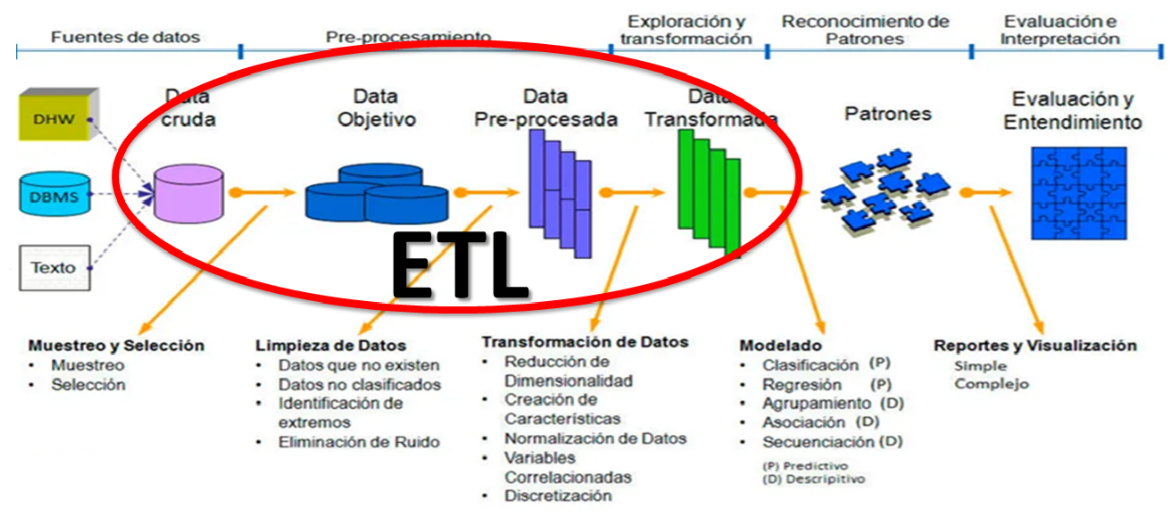

A la hora de realizar el proceso de transformación de un conjunto de datos, hay que tomar **`cinco decisiones`**:

1. Selección de variables o <u>características relevantes</u>

2. Identificación de <u>variables correlacionadas</u>

3. Codificación de <u>variables categóricas</u>

4. <u>Normalización</u> y <u>estandarización</u> de datos

5. <u>Reducción de dimensionalidad</u> de una base de datos

<div style="background-color:#0BF7CC"><b> - $\tt Q_1$: ¿Cómo realizar el proceso de Feature Selection? </b></div>

<u>**Objetivo:**</u> Uno de los aspectos fundamentales en la **selección de variables** es comprobar **si su varianza es cero o cercana a cero**. Esto tiene mucho sentido: si la varianza es cercana a cero, eso significa que NO hay mucha variación dentro de los datos, es decir, que casi todas las observaciones tienen valores similares. Por tanto, las **variables con varianza $0$ suelen ser descartadas**, puesto que es muy probable que solo añadan ruido a nuestro modelo.

**Ejemplo 7 <mark>[Feature Selection con $\tt caret$]</mark>** Podemos comprobar con la librería $\tt caret$ si las observaciones tienen, o no, varianza cero de un modo muy sencillo a través de la función **`nearZeroVar()`**. Veámos cómo funciona con un ejemplo del dataset `Sacramento` que pertenece a esta misma librería, el cual incluye información sobre los precios de las casas en el estado de Sacramento (USA). Primero de todo, vamos a visualizarlo:

In [ ]:
# Cargamos la libería de caret
require(caret)

In [ ]:
# Cargamos la base de datos
data(Sacramento)

In [ ]:
# Visualizamos la estructura
str(Sacramento[1:3,])

'data.frame':	3 obs. of  9 variables:
 $ city     : Factor w/ 37 levels "ANTELOPE","AUBURN",..: 34 34 34
 $ zip      : Factor w/ 68 levels "z95603","z95608",..: 64 52 44
 $ beds     : int  2 3 2
 $ baths    : num  1 1 1
 $ sqft     : int  836 1167 796
 $ type     : Factor w/ 3 levels "Condo","Multi_Family",..: 3 3 3
 $ price    : int  59222 68212 68880
 $ latitude : num  38.6 38.5 38.6
 $ longitude: num  -121 -121 -121


In [ ]:
# Visualizamos las primeras observaciones
head(Sacramento)

,city,zip,beds,baths,sqft,type,price,latitude,longitude
,<fct>,<fct>,<int>,<dbl>,<int>,<fct>,<int>,<dbl>,<dbl>
1,SACRAMENTO,z95838,2,1,836,Residential,59222,38.63191,-121.4349
2,SACRAMENTO,z95823,3,1,1167,Residential,68212,38.47890,-121.4310
3,SACRAMENTO,z95815,2,1,796,Residential,68880,38.61830,-121.4438
4,SACRAMENTO,z95815,2,1,852,Residential,69307,38.61684,-121.4391
5,SACRAMENTO,z95824,2,1,797,Residential,81900,38.51947,-121.4358
6,SACRAMENTO,z95841,3,1,1122,Condo,89921,38.66260,-121.3278


**Nota.** Como vemos, tenemos varias variables numéricas (número de baños, número de camas, precio, latitud y longitud)

In [ ]:
# Tenemos que comprobar cuál de nuestras variables son numéricas previamente
numeric_cols = sapply(Sacramento, is.numeric); numeric_cols

city       zip      beds     baths      sqft      type     price  latitude 
    FALSE     FALSE      TRUE      TRUE      TRUE     FALSE      TRUE      TRUE 
longitude 
     TRUE

In [ ]:
# Veámos si tienen o no varianza cero
variance = nearZeroVar(Sacramento[numeric_cols], saveMetrics = T)
variance

,freqRatio,percentUnique,zeroVar,nzv
,<dbl>,<dbl>,<lgl>,<lgl>
beds,1.623134,0.7510730,FALSE,FALSE
baths,3.022222,0.9656652,FALSE,FALSE
sqft,1.333333,73.7124464,FALSE,FALSE
price,1.111111,64.5922747,FALSE,FALSE
latitude,2.500000,98.7124464,FALSE,FALSE
longitude,2.500000,98.7124464,FALSE,FALSE


**Resultado:** Como vemos, si pasamos el argumento **`saveMetrics = TRUE`**, guarda los valores que ha utilizado para los cálculos. Así pues, uno de los valores que devuelve es **`nzv`** (near-zero-variance), que en <u>todos los casos es falso</u>. Luego, **podemos usar todas nuestras variables numéricas**, al menos de momento.

<div style="background-color:#0BF7CC"><b> - $\tt Q_2$: ¿Cómo encontrar variables correlacionadas? </b></div>

<u>**Objetivo:**</u> Otras de las cuestiones importantes, es la **correlación entre variables**. Existen varios modelos como la regresión lineal y la regresión logística, como veremos en el Tema $3$, cuya condición necesaria es la existencia de correlación entre las variables independientes y la variable dependiente.

**Ejemplo 8 <mark>[Cómo encontrar variables correlacionadas con $\tt cor()$]</mark>** Encontrar variables correlacionadas en R usando la función **`cor()`** es muy sencillo. Veámos cómo funciona con el ejemplo del dataset `Sacramento`:

In [ ]:
# Obtenemos la matriz de correlaciones de las variables numéricas
sacramento_cor = cor(Sacramento[numeric_cols])
sacramento_cor

,beds,baths,sqft,price,latitude,longitude
beds,1.00000000,0.65677220,0.7159079,0.4634122,-0.05362760,0.08368503
baths,0.65677220,1.00000000,0.7607516,0.5756415,0.04723159,0.17991708
sqft,0.71590791,0.76075156,1.0000000,0.7673609,0.04224950,0.23644634
price,0.46341217,0.57564155,0.7673609,1.0000000,0.15480838,0.36302273
latitude,-0.05362760,0.04723159,0.0422495,0.1548084,1.00000000,0.38234665
longitude,0.08368503,0.17991708,0.2364463,0.3630227,0.38234665,1.00000000


**Resultado:** Os lo dejo a ustedes. A la vista de los datos reportados, ¿qué variables NO estarían relacionadas?

<div style="background-color:#0BF7CC"><b> - $\tt Q_3$: ¿Cómo crear variables dummy o ficticias? </b></div>

<u>**Objetivo:**</u> Muchos modelos **NO pueden trabajar con variables categóricas**. En su lugar, tenemos que realizar el proceso de dumificación, es decir **creamos $n-1$ columnas** (donde n es el número de categorías), y que cada una de estas columnas **indica la presencia ($1$) o ausencia ($0$)** de ese valor en concreto. Aunque muchos modelos (como la regresión logística) lo hagan ellos internamente, otros modelos (como xgboost) requieren que lo hagamos nosotros de forma manual.

**Ejemplo 9 <mark>[Variables dummy con $\tt caret$]</mark>** Crear variables dummy con $\tt caret$ es muy sencillo, simplemente tenemos que usar la función **`dummyVars()`** y aplicar la función **`predict()`** para obtener los datos resultantes de dichas variables. Veamos un ejemplo.

In [ ]:
# Visualizamos la base de datos
head(Sacramento)

,city,zip,beds,baths,sqft,type,price,latitude,longitude
,<fct>,<fct>,<int>,<dbl>,<int>,<fct>,<int>,<dbl>,<dbl>
1,SACRAMENTO,z95838,2,1,836,Residential,59222,38.63191,-121.4349
2,SACRAMENTO,z95823,3,1,1167,Residential,68212,38.47890,-121.4310
3,SACRAMENTO,z95815,2,1,796,Residential,68880,38.61830,-121.4438
4,SACRAMENTO,z95815,2,1,852,Residential,69307,38.61684,-121.4391
5,SACRAMENTO,z95824,2,1,797,Residential,81900,38.51947,-121.4358
6,SACRAMENTO,z95841,3,1,1122,Condo,89921,38.66260,-121.3278


In [ ]:
# Vamos a convertir una única columna (type) en tres columnas (una por categoría) cada una de ellas siendo binaria
pre_dummy = dummyVars(~ type, data = Sacramento, drop2nd = T)

In [ ]:
# Creamos las variables ficticias
sacramento_dummy = predict(pre_dummy, Sacramento)

In [ ]:
# Visualizamos las variables dummies creadas
head(sacramento_dummy)

,type.Condo,type.Multi_Family,type.Residential
1,0,0,1
2,0,0,1
3,0,0,1
4,0,0,1
5,0,0,1
6,1,0,0


**Nota.** Vemos cómo hemos creado tres variables ficticias (dummies) a partir de una categórica siendo estas binarias (numéricas). Esto se realiza muy a menudo cuando queremos **convertir variables categóricas** en **numéricas** o en **binarias** (si queremos tener un problema con dos clases).

<div style="background-color:#0BF7CC"><b> - $\tt Q_4$: ¿Cómo escalar o normalizar los valores de una variable? </b></div>

<u>**Objetivo:**</u> Consiste en **normalizar la escala de los datos**, ya que esta es muy importante en algoritmos como los modelos de clasificación, regularización o clustering, entre otros. De hecho, es un paso previo que tenemos que hacer siempre que queramos utilizar esos modelos. Además, este proceso permite comparar y combinar variables que originalmente están en diferentes escalas o unidades de medida y evita que variables con escalas mayores dominen el análisis o modelo.

**Ejemplo 10a <mark>[Escalar o normalizar datos con $\tt caret$]</mark>** Para escalar los datos, simplemente tenemos que pasar argumentos al parámetro `method` de la función **`preProcess()`** de la librería $\tt caret$. Esta función acepta los siguientes valores:

- `center`: resta el promedio a los valores, de tal forma que todos tengan promedio $0$. Esto centra la distribución de la variable en el origen del eje horizontal.
- `scale`: divide los valores entre la desviación estándar. De esta forma, los datos tendrán desviación típica $1$. Esto significa que la distribución tiene una variabilidad uniforme.
- `range`: normaliza los datos, haciendo que estos tengan un rango de $0$ a $1$ (probabilidades).

In [ ]:
# Normalizamos la base de datos Sacramento utilizando el método center
datos_center = preProcess(Sacramento, method = "center"); datos_center

Created from 932 samples and 9 variables

Pre-processing:
  - centered (6)
  - ignored (3)


In [ ]:
# Visualizamos la estructura de dicha transformación
str(datos_center)

List of 21
 $ dim              : int [1:2] 932 9
 $ bc               : NULL
 $ yj               : NULL
 $ et               : NULL
 $ invHyperbolicSine: NULL
 $ mean             : Named num [1:6] 3.28 2.05 1.68e+03 2.47e+05 3.86e+01 ...
  ..- attr(*, "names")= chr [1:6] "beds" "baths" "sqft" "price" ...
 $ std              : NULL
 $ ranges           : NULL
 $ rotation         : NULL
 $ method           :List of 2
  ..$ center: chr [1:6] "beds" "baths" "sqft" "price" ...
  ..$ ignore: chr [1:3] "city" "zip" "type"
 $ thresh           : num 0.95
 $ pcaComp          : NULL
 $ numComp          : NULL
 $ ica              : NULL
 $ wildcards        :List of 2
  ..$ PCA: chr(0) 
  ..$ ICA: chr(0) 
 $ k                : num 5
 $ knnSummary       :function (x, ...)  
 $ bagImp           : NULL
 $ median           : NULL
 $ data             : NULL
 $ rangeBounds      : num [1:2] 0 1
 - attr(*, "class")= chr "preProcess"


**Resultado:** Como vemos, la librería $\tt caret$ ha centrado los datos de $6$ variables, correspondientes a las **variables numéricas**, ignorando $3$ variables. Vemos el mensaje, pero no los datos. ¿Por qué?</u> La razón es que, la función **`preProcess()`** NO está pensada para transformar los datos en el momento, sino para hacer la **transformación** en el **proceso de entrenamiento**.

**Ejemplo 10b <mark>[Escalar o normalizar datos con $\tt caret$]</mark>** Sin embargo, existe una alternativa par sin entrenar el modelo **SI que podamos ver cómo quedan** nuestros datos. Para ello, tenemos que pasar el preprocesamiento y nuestros datos a la función **`predict()`**. Veámos cómo funciona.

In [ ]:
# Normalizamos la base de datos Sacramento utilizando el método center
preprocess = preProcess(Sacramento, method = "center"); preprocess

Created from 932 samples and 9 variables

Pre-processing:
  - centered (6)
  - ignored (3)


In [ ]:
# Aplicamos dicha transformación a nuestra base de datos
predict(preprocess, Sacramento)[1:6,]

,city,zip,beds,baths,sqft,type,price,latitude,longitude
,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>
1,SACRAMENTO,z95838,-1.2757511,-1.053112,-844.3187,Residential,-187439.6,0.03893321,-0.07459136
2,SACRAMENTO,z95823,-0.2757511,-1.053112,-513.3187,Residential,-178449.6,-0.11407779,-0.07074036
3,SACRAMENTO,z95815,-1.2757511,-1.053112,-884.3187,Residential,-177781.6,0.02532521,-0.08355136
4,SACRAMENTO,z95815,-1.2757511,-1.053112,-828.3187,Residential,-177354.6,0.02385521,-0.07885836
5,SACRAMENTO,z95824,-1.2757511,-1.053112,-883.3187,Residential,-164761.6,-0.07350979,-0.07548036
6,SACRAMENTO,z95841,-0.2757511,-1.053112,-558.3187,Condo,-156740.6,0.06961521,0.03247464


In [ ]:
# Comparamos con los datos originales
head(Sacramento)

,city,zip,beds,baths,sqft,type,price,latitude,longitude
,<fct>,<fct>,<int>,<dbl>,<int>,<fct>,<int>,<dbl>,<dbl>
1,SACRAMENTO,z95838,2,1,836,Residential,59222,38.63191,-121.4349
2,SACRAMENTO,z95823,3,1,1167,Residential,68212,38.47890,-121.4310
3,SACRAMENTO,z95815,2,1,796,Residential,68880,38.61830,-121.4438
4,SACRAMENTO,z95815,2,1,852,Residential,69307,38.61684,-121.4391
5,SACRAMENTO,z95824,2,1,797,Residential,81900,38.51947,-121.4358
6,SACRAMENTO,z95841,3,1,1122,Condo,89921,38.66260,-121.3278


**Ejemplo 10c <mark>[Escalar o normalizar datos con $\tt caret$]</mark>** Como vemos, **ahora SÍ que $\tt caret$ nos devuelve todos los datos con el procesamiento ya aplicado** (en este caso, habiendo restado la media). Veámos otro ejemplo para normalizar los datos en el rango entre $0$ y $1$.

In [ ]:
# Normalizamos la base de datos Sacramento utilizando el método range
preprocess = preProcess(Sacramento, method = "range"); preprocess

Created from 932 samples and 9 variables

Pre-processing:
  - ignored (3)
  - re-scaling to [0, 1] (6)


In [ ]:
# Aplicamos dicha transformación a nuestra base de datos
Sacramento_processed = predict(preprocess, Sacramento)

In [ ]:
# Visualizamos los datos transformados
head(Sacramento_processed)

,city,zip,beds,baths,sqft,type,price,latitude,longitude
,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>
1,SACRAMENTO,z95838,0.1428571,0,0.08010924,Residential,0.03418617,0.5009650,0.1224446
2,SACRAMENTO,z95823,0.2857143,0,0.15543924,Residential,0.04470338,0.3046193,0.1264808
3,SACRAMENTO,z95815,0.1428571,0,0.07100592,Residential,0.04548486,0.4835030,0.1130536
4,SACRAMENTO,z95815,0.1428571,0,0.08375057,Residential,0.04598439,0.4816167,0.1179723
5,SACRAMENTO,z95824,0.1428571,0,0.07123350,Residential,0.06071667,0.3566767,0.1215128
6,SACRAMENTO,z95841,0.2857143,0,0.14519800,Condo,0.07010026,0.5403365,0.2346608


In [ ]:
# Comparamos con los datos originales
head(Sacramento)

,city,zip,beds,baths,sqft,type,price,latitude,longitude
,<fct>,<fct>,<int>,<dbl>,<int>,<fct>,<int>,<dbl>,<dbl>
1,SACRAMENTO,z95838,2,1,836,Residential,59222,38.63191,-121.4349
2,SACRAMENTO,z95823,3,1,1167,Residential,68212,38.47890,-121.4310
3,SACRAMENTO,z95815,2,1,796,Residential,68880,38.61830,-121.4438
4,SACRAMENTO,z95815,2,1,852,Residential,69307,38.61684,-121.4391
5,SACRAMENTO,z95824,2,1,797,Residential,81900,38.51947,-121.4358
6,SACRAMENTO,z95841,3,1,1122,Condo,89921,38.66260,-121.3278


In [ ]:
# Hacemos un pequeño estudio comparativo para verificar que los hemos transformado correctamente
cat("--- Datos sin procesar ---","\n",
    "Min:", min(Sacramento$sqft),"\n",
    "Max:", max(Sacramento$sqft), "\n","\n",
    "--- Datos procesados ---","\n",
    "Min:", min(Sacramento_processed$sqft),"\n",
    "Max:", max(Sacramento_processed$sqft)
    )

--- Datos sin procesar --- 
 Min: 484 
 Max: 4878 
 
 --- Datos procesados --- 
 Min: 0 
 Max: 1

**Resultados:** Como vemos, hemos normalizado los datos simplemente con una línea de código. En resumen, una variable con media cero y desviación típica uno ha sido transformada para que su distribución esté centrada y escalada uniformemente. Esta transformación es fundamental en el preprocesamiento de datos para análisis estadísticos y modelos de aprendizaje automático, ya que:

- Facilita la convergencia y estabilidad de los algoritmos.
- Permite una interpretación más sencilla de los datos.
- Asegura que todas las variables influyen de manera equilibrada en el análisis.

<div style="background-color:#0BF7CC"><b> - $\tt Q_5$: ¿Cómo reducir la dimensionalidad o número de variables?  </b></div>

<u>**Objetivo:**</u> Cuando trabajamos en un problema con un alto nivel de dimensionalidad, es decir, con **muchas variables**, suele ser interesante **reducir el número** de variables **manteniendo** la **mayor cantidad** de **información posible**. Este proceso se suele realizar con un `Análisis de Componentes Principales (PCA)` para identificar cuáles son las variables más importantes.

**Ejemplo 11 <mark>[Reducir la dimensionalidad con $\tt caret$]</mark>** Cuando trabajamos en problemas de ML o DL con demasiadas variables, muchas veces solemos tener problemas. Y es que, la gran mayoría de modelos NO funcionan bien con muchas variables y, si lo hace, requieren de muchos datos. En estos casos una buena opción suele ser aplicar un método de reducción de la dimensionalidad como el PCA.

En R para aplicar un PCA sobre nuestro dataset utilizaremos, nuevamente, la librería $\tt caret$. Para ello, simplemente debemos indicar el valor `pca` al parámetro *`method`* de la función **`preProcess()`**. Asimismo, con el parámetro *`thresh`* podemos indicar el porcentaje de la variabilidad con la que nos queremos quedar.

In [ ]:
# Cargamos la base de datos Sacramento
data(Sacramento)

In [ ]:
# Definimos el método de Análisis de Componentes Principales
pre_pca = preProcess(Sacramento, method = "pca", thresh = 0.8)

In [ ]:
# Visualizamos la información tras aplicar dicha técnica (de momento - no vamos a profundizar en ella)
str(pre_pca)

List of 21
 $ dim              : int [1:2] 932 9
 $ bc               : NULL
 $ yj               : NULL
 $ et               : NULL
 $ invHyperbolicSine: NULL
 $ mean             : Named num [1:6] 3.28 2.05 1.68e+03 2.47e+05 3.86e+01 ...
  ..- attr(*, "names")= chr [1:6] "beds" "baths" "sqft" "price" ...
 $ std              : Named num [1:6] 8.88e-01 7.23e-01 7.26e+02 1.31e+05 1.34e-01 ...
  ..- attr(*, "names")= chr [1:6] "beds" "baths" "sqft" "price" ...
 $ ranges           : NULL
 $ rotation         : num [1:6, 1:3] 0.4477 0.4866 0.5321 0.4739 0.0855 ...
  ..- attr(*, "dimnames")=List of 2
  .. ..$ : chr [1:6] "beds" "baths" "sqft" "price" ...
  .. ..$ : chr [1:3] "PC1" "PC2" "PC3"
 $ method           :List of 4
  ..$ pca   : chr [1:6] "beds" "baths" "sqft" "price" ...
  ..$ ignore: chr [1:3] "city" "zip" "type"
  ..$ center: chr [1:6] "beds" "baths" "sqft" "price" ...
  ..$ scale : chr [1:6] "beds" "baths" "sqft" "price" ...
 $ thresh           : num 0.8
 $ pcaComp          : NULL
 $

In [ ]:
# Aplicamos dicha técnica a nuestra base de datos
predict(pre_pca, Sacramento)

,city,zip,type,PC1,PC2,PC3
,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>
1,SACRAMENTO,z95838,Residential,-2.7398850,-0.43605397,0.28834605
2,SACRAMENTO,z95823,Residential,-2.0522123,0.69520462,-0.29507984
3,SACRAMENTO,z95815,Residential,-2.7569171,-0.33961807,0.23841327
4,SACRAMENTO,z95815,Residential,-2.7079730,-0.34492865,0.20908426
5,SACRAMENTO,z95824,Residential,-2.7595432,0.12722856,-0.33904501
6,SACRAMENTO,z95841,Condo,-1.7288112,-0.74681258,0.18708446
7,SACRAMENTO,z95842,Residential,-1.0900917,-0.54677968,0.63324837
8,SACRAMENTO,z95820,Residential,-2.0051452,0.60954011,0.17535425
9,RANCHO_CORDOVA,z95670,Condo,-1.6113163,-0.93354576,-0.29589621


**Resultados:** Como vemos, ahora el dataset cuenta con $6$ columnas en vez de $9$. Hemos **reducido el nº variables numéricas** en un $50\%$ **perdiendo** solamente $20\%$ de la información. Sí, lo sé, este NO es el mejor ejemplo en el cual aplicar un PCA aporta mucho valor, pero, como vemos, podemos hacerlo y de una forma muy sencilla gracias a la libería $\tt caret$. Veremos esta técnica con mayor detalle más adelante.

# 4. ¿En qué consiste el proceso de limpieza de una BD? <a id="topic2"></a>&nbsp;&nbsp;<a href="#index"><i class="fa fa-list-alt" aria-hidden="true"></i></a>

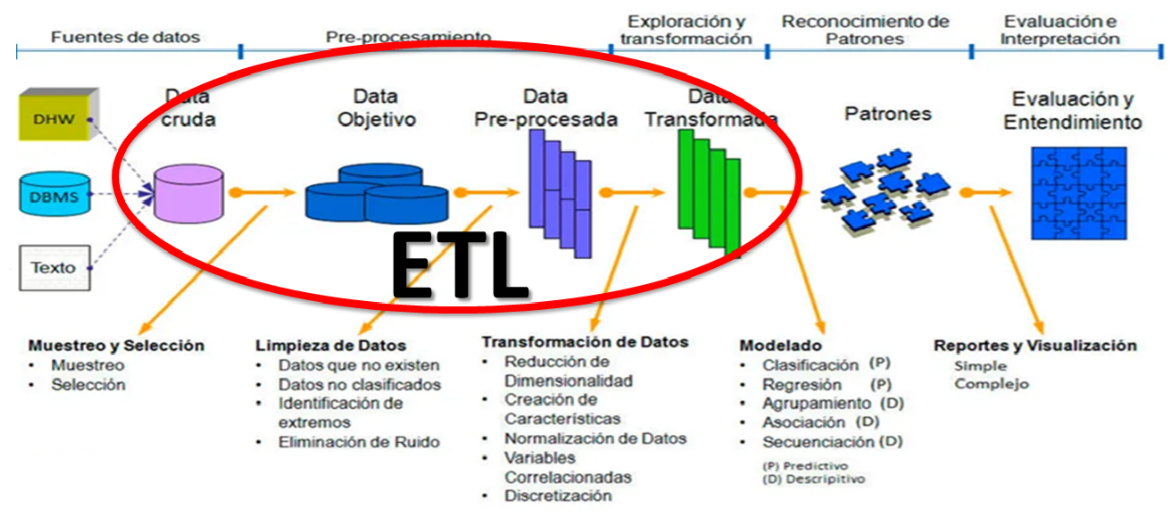

A la hora de realizar el proceso de limpieza de un conjunto de datos, hay que tomar **`dos decisiones`**:

1. Tratamiento de <u>datos faltantes</u> de una base de datos

2. Identificación de <u>valores atípicos</u> de una base de datos

<div style="background-color:#0BF7CC"><b> - $\tt Q_1$: ¿Cómo realizamos el tratamiento de los valores perdidos? </b></div>

In [ ]:
# Cargamos la base de datos iris, por ejemplo.
data(iris)

In [ ]:
# Estructura de la base de datos 'iris'
str(iris)

'data.frame':	150 obs. of  5 variables:
 $ Sepal.Length: num  5.1 4.9 4.7 4.6 5 5.4 4.6 5 4.4 4.9 ...
 $ Sepal.Width : num  3.5 3 3.2 3.1 3.6 3.9 3.4 3.4 2.9 3.1 ...
 $ Petal.Length: num  1.4 1.4 1.3 1.5 1.4 1.7 1.4 1.5 1.4 1.5 ...
 $ Petal.Width : num  0.2 0.2 0.2 0.2 0.2 0.4 0.3 0.2 0.2 0.1 ...
 $ Species     : Factor w/ 3 levels "setosa","versicolor",..: 1 1 1 1 1 1 1 1 1 1 ...


In [ ]:
# Comprobamos si existen datos NAs para en caso afirmativo, eliminarlos y que no nos den problemas
data=na.omit(iris)

In [ ]:
# Podemos comprobar que no existen datos NAs
nrow(iris) # Base de datos inicial
nrow(data) # Base de datos tras el na.omit

[1] 150

[1] 150

<u>**Objetivo:**</u> La gran mayoría de modelos **NO pueden trabajar** con valores perdidos. Es por ello que, **cuando tenemos** valores perdidos tenemos que **imputar o eliminar** esas observaciones o variables. La libería $\tt caret$ permite imputar valores perdidos usando varios tipos de modelos de una forma muy sencilla.

**Ejemplo 12 <mark>[Imputar valores perdidos con $\tt caret$]</mark>** Para imputar valores perdidos con la librería $\tt caret$, usaremos nuevamente la función **`preProcess()`**. En este caso, hay diferentes valores que le podemos pasar al parámetro *`method`*:

- `knnImpute`: permite utilizar el algoritmo kNN para imputar valores perdidos. El algoritmo kNN requiere que le indiques el número de vecinos a utilizar en la predicción. Es por ello que, si usamos el método knnImpute, también tendremos que indicar el parámetro `k`. **NO lo utilizaremos de momento**.

- `medianImpute`: como su nombre indica, imputa la mediana (en caso de una variable numérica). Esto suele ser preferible a imputar la media, puesto que el promedio puede verse afectado por outliers como vimos en el Notebook anterior.

Para ello, lo primero de todo, **vamos a “eliminar”** algunos datos de nuestro dataset para **simular que tenemos valores perdidos**. Eliminar datos intencionadamente de un dataset para simular la presencia de datos faltantes **puede ser útil** para probar la robustez de los métodos de imputación o para **evaluar el impacto** de los **datos faltantes** en el **rendimiento** de los modelos de ML o DL utilizados. A continuación, presento un método simple para eliminar datos al azar de un dataset precargado:

In [ ]:
# Establecemos una semilla para reproducibilidad
set.seed(123)

In [ ]:
# Definimos el porcentaje de datos a eliminar
porcentaje = 0.1 # 10% de los datos

In [ ]:
# Calculamos el número de valores a eliminar
n = nrow(Sacramento) * ncol(Sacramento); n
n_eliminar = floor(n * porcentaje); n_eliminar # función floor nos quedamos con el número entero sin decimales

[1] 8388

[1] 838

In [ ]:
# Generamos índices aleatorios
indices = sample(1:n, n_eliminar); indices

[1] 2463 2511 2986 1842 3371 4761 6746 2757 5107 2888 6170 2567 2980 1614  555
 [16] 4469 7789 1047 7067 3004 3207 7989 3995 8358  217 8157 6216 1599 4237 3937
 [31] 4089 2907  294   41 7391 6672 7284 2504 6742 6129 4612 2117 6134  755 6553
 [46] 5428 7127 3358 3980 3230 5603 4576 3783 7831 5967 7816 1386 4706 2378 4044
 [61]  686 6078 5027 6387 7281 4715  151 6810 8174 6911 2208 1029 7448 7735 8011
 [76] 1956 8172 5358 5884 4093  985 6183  986 4233 1584 4685 7864 4776 6644 8308
 [91] 7478 2507  195 3124 6678 4650 2132 3464 3949 7757 2758 3833  712 5370 3501
[106] 3069 4055  473 6098 1149 2037 2313 7741 1078 5015 5658 6379 1313  185 7933
[121]  413 4723 1333 4875  564 3799 4256 3581 3129 6601 4713  279 4366 6790 6491
[136] 3201 2266  618 1905  539 3625 6868 3462 5618 6815 7005 6801 3008 6804 2211
[151] 2286 5793 7684 8330 5509 4213 7826 1706 7879 8081  988 8367 4807 5588 3809
[166] 7426 2225 1165 6083 7634 2213 1612 3853 5565  710 8042 1258 2470 2112 6224
[181] 3035 2339 6909 1347 6623 7728 5001 5407 5854 4388 5346 1708 4701 1835 3111
[196] 6309 8323 1057   83 3468  866 2325 7377 5119 4172 5214 7971 7198 7385 7090
[211] 7343 6518 2371 2163 5497 6994 2656 7633 5478  682 1448 7082 3168 1562 6541
[226] 7572 3814 7316  989 4052 8030 1961 6536 4007 5834 2641 5567 1362 6888 4339
[241] 2154 3959 6155 4721 3436  386 2451 4557  141   31 6046 5235 5910 4190 3786
[256] 4112 3781 7588  178 3489 3536 5532 6321 4620 5557 5020 5698 7730  204 3247
[271] 4019 2421 8255 7632 2432 5242 7567 3475 2363  259 4590 5985 5880 5409 7216
[286] 1355 7268 3064 5228 1325 4106 4266 3352 7516 4071 2450 1233 3540 1851 1673
[301] 7477 3467 4204 4104 4722 4357 2589 7474 6470 5194 2330 1609 3339 6007 5382
[316] 1760 8120 5843 5339 6840 3424  667 5086 5239 4548  856 1948 5699 2670 1960
[331]  646 1060 3127 3562 1264 4987 1656 1886 1328 4084 3082  665 3494 2035 5732
[346] 3177 4889 5508 8387 1204 4374 7541  241 4120 6823 7727 1727 2085 2734 6710
[361] 5423 1743 3984 6163 7880 5791  378  549 5735 1268 2096 7356 4030 6608 4489
[376] 3211 8384 1395 4766 5309  311 6333 1442 7737 5502 2086 1108  319 6830 2894
[391] 1862 7570 1666  120 2760 7499 1557 6585 7367 3571  599 8362 5435 6858 6821
[406] 6225 5175  134 4520 2804 6150 3200  879  668 5920   49 7907 5596 3311 7508
[421]  193 8381 6603 4399 8161 7042 2238 3696  191 6590 6263 3699 7690 5747 7227
[436] 4913 3975 2109 1446 3180 1316 1397 5655 8175 2978 5720 3716 5046 5533 4794
[451] 8342 5883 5323  758 5089 3318 1464 2995 6834  251 2608  643 2593  990 2210
[466] 5442 2624 6312 3514 6932 6222 8047 1517 7990 5544  445 3043   95 3990 8128
[481]  379 1366 2269 8069 7329  620  448  242 7861 7071 2862 6088 7704 7070  407
[496] 6373 7392 2833 1498 2747 1465 3243 3095 4314 3556 7469 4744   79 7679 1531
[511] 3236 6381 4675 1831 2977 4518 4589 4826 1820 2257 4695 3765 7526 7818  877
[526] 2406 5161  904 7297 4944 7030 4546 1256 1358 2444 3802 1864 2687 4137 3336
[541] 3769  201   52 5345 2115  680 3842  577 4553 1015 1927 4045 5661 5140 1230
[556] 2172 2640 3847 2788 6189 7500 3353 2139 6797 2004 7306  606 6271 7593 3080
[571]  839 6137 7439 6739 2795 3239 4595 7423 7988 1658  931 2950   71 5892 4042
[586] 4177 4016 6920 7605 7747 4972 4992 3509 5870 7141  270 1436 5766 6281 2721
[601] 4724 5166 8210 2579 7893 5730 7860 7388 3294  836 8230  602 7290  331 4997
[616] 6646 7652 5907  291 4001 4839 4925  919 3241 2777 1471 6136 7729 1365 8347
[631] 7488  504 3148 1026 2934  786 1796 7274 3183  855 4470 1096  449 7032 3019
[646] 3301 1547 4431 3001 3128 8251 6415 4303  436 2924 3049 4029  601 7948  387
[661] 3335 3140 3192 2792 6709 5477 2840  742 7779 1859 4619 4682  256 3421 7639
[676] 7774 4184 5536 5977 2059  586 4559 3827 2748 7455 6986 4781 3899 6424 3584
[691]  803 2290  778 5184 1352 6316 5418 8318 1703 1553 6612 7552  929 2789 6090
[706] 2413 1994 6018 2639 3543 3951 2024 5347 2882 5742 1339 4015 2291 3337  535
[721] 8213  982 2160 4552 3165 7657  789 6775 8018 3017 4578 1272 2153 1195 4792
[736]  459 6660 2887 5432 5682 29

In [ ]:
# Función auxiliar para convertir índices lineales en índices de matriz (coordenadas de fila y columna)
ind2ij = function(ind, nc) {
  cbind((ind - 1) %/% nc + 1, (ind - 1) %% nc + 1) # %/% división entera descartando en el resultado los decimales
}

**Nota.** La función **`ind2ij()`** es una función auxiliar para convertir índices lineales (como los generados por `sample`) en índices de matriz que R puede usar para indexar el dataframe `Sacramento`. Esto es necesario porque `Sacramento` es un dataframe, y para asignar $\tt NA$ a entradas específicas necesitamos especificar tanto las filas como las columnas.

In [ ]:
# Reemplazamos los valores seleccionados por NA
Sacramento[as.matrix(ind2ij(indices, ncol(Sacramento)))] = NA

In [ ]:
# Visualizamos la nueva base de datos
head(Sacramento)

,city,zip,beds,baths,sqft,type,price,latitude,longitude
,<fct>,<fct>,<int>,<dbl>,<int>,<fct>,<int>,<dbl>,<dbl>
1,SACRAMENTO,z95838,2,1,836,Residential,59222,38.63191,-121.4349
2,SACRAMENTO,z95823,3,1,1167,Residential,68212,38.47890,-121.4310
3,SACRAMENTO,z95815,2,1,796,Residential,68880,38.61830,-121.4438
4,SACRAMENTO,z95815,2,NA,852,Residential,69307,38.61684,-121.4391
5,SACRAMENTO,z95824,2,1,NA,Residential,81900,38.51947,-121.4358
6,SACRAMENTO,z95841,3,NA,1122,Condo,NA,38.66260,-121.3278


**Nota.** Este método es bastante flexible y puede ser ajustado para eliminar diferentes porcentajes de datos o para enfocarse en columnas específicas, lo que puede ser útil para simular escenarios específicos donde algunos tipos de datos de determinadas variables son más propensos a faltar que otros.

In [ ]:
# Contamos cuántos NAs hay en cada una de las variables
colSums(is.na(Sacramento))

city       zip      beds     baths      sqft      type     price  latitude 
       88       100        82        79        91       108       107       104 
longitude 
       79

In [ ]:
# Imputación datos faltantes considerando la mediana
pre_median = preProcess(Sacramento, method = "medianImpute")

In [ ]:
# Aplicamos dichas imputaciones a nuestra base de datos
imputed_median = predict(pre_median, Sacramento)

In [ ]:
# Visualizamos la nueva base de datos (median)
head(imputed_median)

,city,zip,beds,baths,sqft,type,price,latitude,longitude
,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>
1,SACRAMENTO,z95838,2,1,836,Residential,59222,38.63191,-121.4349
2,SACRAMENTO,z95823,3,1,1167,Residential,68212,38.47890,-121.4310
3,SACRAMENTO,z95815,2,1,796,Residential,68880,38.61830,-121.4438
4,SACRAMENTO,z95815,2,2,852,Residential,69307,38.61684,-121.4391
5,SACRAMENTO,z95824,2,1,1477,Residential,81900,38.51947,-121.4358
6,SACRAMENTO,z95841,3,2,1122,Condo,220000,38.66260,-121.3278


**Resultado:** Como vemos, hemos podido realizar la imputación de los valores perdidos de una forma muy sencilla. No entraremos en más detalle sobre las técnicas de imputación de datos faltantes de momento. Lo trataremos en próximos temas.

<div style="background-color:#0BF7CC"><b> - $\tt Q_2$: ¿Cómo identificamos los valores atípicos de una base de datos? </b></div>

<u>**Objetivo:**</u> Un valor atípico es una **observación** en un conjunto de datos que **se desvía significativamente** de otras observaciones. Los valores atípicos pueden indicar variabilidad en la medición, errores en los datos o fenómenos inusuales. Identificarlos es crucial, ya que pueden influir en los análisis estadísticos y en el rendimiento de los modelos de ML y DL.

**Ejemplo 13 <mark>[Identificar valores atípicos con `boxplot()`]</mark>** Para identificar los valores atípicos lo haremos obteniendo evidencias gráficas sobre dichos valores. Veamos un ejemplo de este último concepto con el dataset utilizado `Sacramento`.

In [ ]:
# Cargamos el conjunto de datos Sacramento
data(Sacramento)

In [ ]:
# Exploramos las primeras filas del conjunto de datos
head(Sacramento)

,city,zip,beds,baths,sqft,type,price,latitude,longitude
,<fct>,<fct>,<int>,<dbl>,<int>,<fct>,<int>,<dbl>,<dbl>
1,SACRAMENTO,z95838,2,1,836,Residential,59222,38.63191,-121.4349
2,SACRAMENTO,z95823,3,1,1167,Residential,68212,38.47890,-121.4310
3,SACRAMENTO,z95815,2,1,796,Residential,68880,38.61830,-121.4438
4,SACRAMENTO,z95815,2,1,852,Residential,69307,38.61684,-121.4391
5,SACRAMENTO,z95824,2,1,797,Residential,81900,38.51947,-121.4358
6,SACRAMENTO,z95841,3,1,1122,Condo,89921,38.66260,-121.3278


In [ ]:
# Obtenemos un resumen estadístico de la variable 'price'
summary(Sacramento$price)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  30000  156000  220000  246662  305000  884790 

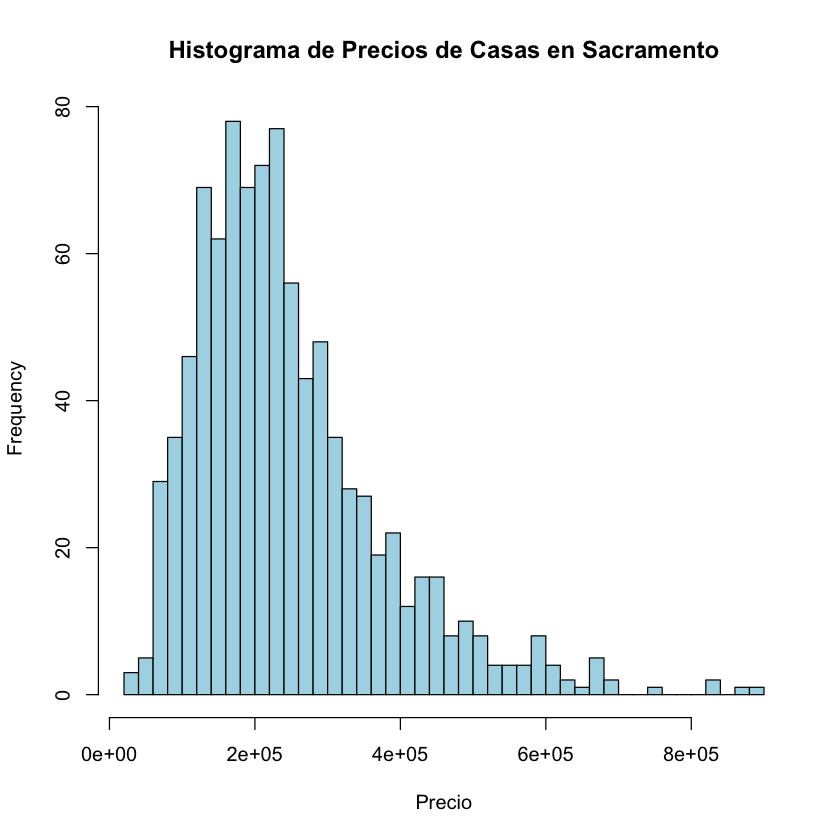

In [ ]:
# Visualizamos la distribución de los precios con un histograma
hist(Sacramento$price, breaks = 50, main = "Histograma de Precios de Casas en Sacramento", xlab = "Precio", col = "lightblue")

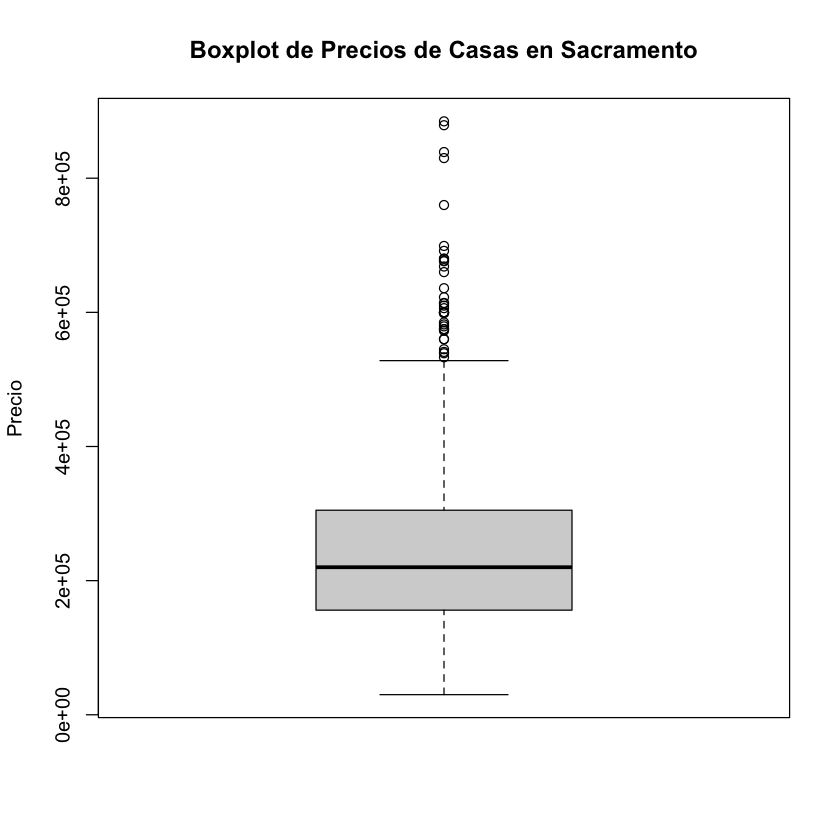

In [ ]:
# Visualizamos posibles valores atípicos con un diagrama de caja y bigotes (boxplot)
boxplot(Sacramento$price, main = "Boxplot de Precios de Casas en Sacramento", ylab = "Precio")

Veamos una **explicación del gráfico boxplot**:

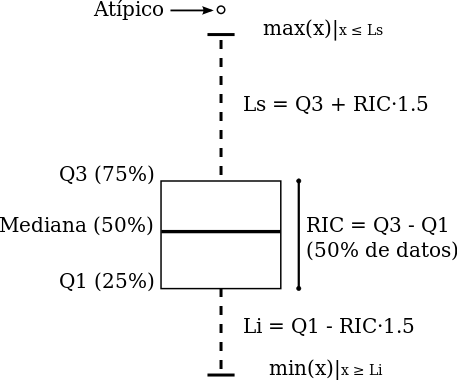

In [ ]:
# Identificamos los valores atípicos utilizando el método del Rango Intercuartílico (IQR)
Q1 = quantile(Sacramento$price, 0.25)
Q3 = quantile(Sacramento$price, 0.75)
IQR = Q3 - Q1; IQR

75% 
149000

In [ ]:
# Definimos los límites inferior y superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

In [ ]:
# Imprimimos los límites
cat("Límite Inferior:", limite_inferior, "\n")
cat("Límite Superior:", limite_superior, "\n")

Límite Inferior: -67500 
Límite Superior: 528500 


In [ ]:
# Identificamos los valores atípicos
atipicos = Sacramento$price[Sacramento$price < limite_inferior | Sacramento$price > limite_superior]

In [ ]:
# Número de valores atípicos
cat("Número de valores atípicos:", length(atipicos), "\n")

Número de valores atípicos: 37 


In [ ]:
# Mostramos los valores atípicos
atipicos

[1] 539000 585000 600000 606238 660000 830000 541000 560000 572500 582000
[11] 613401 614000 680000 699000 839000 579093 636000 668365 676200 677048
[21] 691659 760000 533000 545000 560000 575000 575000 598695 600000 600000
[31] 600000 600000 610000 622500 680000 879000 884790

In [ ]:
# Analizamos las observaciones que son valores atípicos
atipicos2 = Sacramento[Sacramento$price < limite_inferior | Sacramento$price > limite_superior, ]
head(atipicos2)

,city,zip,beds,baths,sqft,type,price,latitude,longitude
,<fct>,<fct>,<int>,<dbl>,<int>,<fct>,<int>,<dbl>,<dbl>
153,FOLSOM,z95630,4,2,2462,Residential,539000,38.65517,-121.0902
154,FOLSOM,z95630,5,3,2900,Residential,585000,38.67095,-121.0977
155,EL_DORADO_HILLS,z95762,4,4,3705,Residential,600000,38.67276,-121.0504
156,EL_DORADO_HILLS,z95762,4,3,3527,Residential,606238,38.66681,-121.0648
157,SACRAMENTO,z95864,3,3,2325,Residential,660000,38.59162,-121.3706
158,EL_DORADO_HILLS,z95762,6,5,4878,Residential,830000,38.66993,-121.0596


<div style = "float:right"><a style="text-decoration:none" href = "#inicio">Inicio</a></div>